
# FlashPoint: staged spatiotemporal position reconstruction

Supports:

$$
N_{\rm EDGE}=0,1,2,3
\quad\Rightarrow\quad
4,8,12,16\ {\rm SiPMs}.
$$

Study order:

1. Conventional COG baselines;
2. full-amplitude template likelihood;
3. amplitude + first-photon timing;
4. amplitude + first-3-photon timing;
5. amplitude + early-photon \(dN/dt\);
6. full binned spatiotemporal Poisson likelihood;
7. optional ExtraTrees nonlinear baseline;
8. approximate Fisher-information / CRLB check for the \(\sim10\) mm target.

Timing is aligned event-by-event to the **earliest detected photon in the whole detector**, so the reconstruction uses relative timing rather than the unknown absolute event time.

The early \(dN/dt\) representation is first built at **50 ps/bin** and rebinned to **100 ps/bin** for the main reconstruction. Change the configuration below if memory is limited.


In [58]:

# 0. Imports + configuration
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

from sklearn.ensemble import HistGradientBoostingRegressor, ExtraTreesRegressor

warnings.filterwarnings("ignore")
SEED=42
rng=np.random.default_rng(SEED)

# NEDGE = 0, 1, 2, 3 -> 4, 8, 12, 16 SiPMs
NEDGE=3

RUN=Path("/Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies")
INDIR=RUN/f"output_edge{NEDGE}"
FILES=sorted(INDIR.glob("*.root"))
OUT=RUN/f"output_edge{NEDGE}_analysis_spatiotemporal"; OUT.mkdir(parents=True,exist_ok=True)

if not FILES:
    raise FileNotFoundError(f"No ROOT files found in {INDIR}")

NSIPM=4+4*NEDGE
TRAIN_FRAC=.70

# spatial response templates
GRID_N=40                 # 40x40 -> nominal 25 mm cells over 1 m
MIN_CELL=10
POSTERIOR_K=9             # local interpolation from best K template cells
LIKELIHOOD_CHUNK=2000

# early dN/dt
DT_FINE_NS=.05            # 50 ps master bin
EARLY_NS=3.0
DND_REBIN=2               # main reconstruction: 100 ps/bin
NBIN_FINE=int(round(EARLY_NS/DT_FINE_NS))

# nonlinear regression
HGB_MAX_ITER=180
HGB_LEAVES=31
ML_TRAIN_MAX=100_000

# optional expensive studies
RUN_EXTRA_TREES=False
RUN_TIMING_BIN_SCAN=False

print(f"NEDGE={NEDGE} -> NSIPM={NSIPM}")
print(f"ROOT files={len(FILES)}")
print(f"dN/dt master bin={DT_FINE_NS*1e3:.0f} ps, main bin={DT_FINE_NS*DND_REBIN*1e3:.0f} ps")


NEDGE=3 -> NSIPM=16
ROOT files=20
dN/dt master bin=50 ps, main bin=100 ps


SiPM  0: (  497.854,  497.854) mm
SiPM  1: ( -497.854,  497.854) mm
SiPM  2: ( -497.854, -497.854) mm
SiPM  3: (  497.854, -497.854) mm
SiPM  4: ( -250.000,  500.000) mm
SiPM  5: (    0.000,  500.000) mm
SiPM  6: (  250.000,  500.000) mm
SiPM  7: (  500.000,  250.000) mm
SiPM  8: (  500.000,   -0.000) mm
SiPM  9: (  500.000, -250.000) mm
SiPM 10: (  250.000, -500.000) mm
SiPM 11: (   -0.000, -500.000) mm
SiPM 12: ( -250.000, -500.000) mm
SiPM 13: ( -500.000, -250.000) mm
SiPM 14: ( -500.000,    0.000) mm
SiPM 15: ( -500.000,  250.000) mm


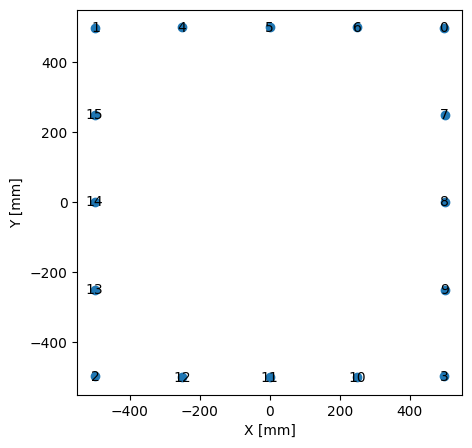

In [59]:

# 1. Exact SiPM optical-contact positions used for conventional COG
def get_POS(NEDGE):
    c=497.8539309191
    pos=[[ c, c],[-c, c],[-c,-c],[ c,-c]]

    if NEDGE:
        u=np.linspace(-500,500,NEDGE+2)[1:-1]
        pos += [[ x, 500] for x in u]       # +Y: left -> right
        pos += [[500,-y] for y in u]        # +X: top -> bottom
        pos += [[-x,-500] for x in u]       # -Y: right -> left
        pos += [[-500,y] for y in u]        # -X: bottom -> top

    return np.asarray(pos,float)

POS=get_POS(NEDGE)
assert len(POS)==NSIPM

for i,(x,y) in enumerate(POS):
    print(f"SiPM {i:2d}: ({x:9.3f},{y:9.3f}) mm")

fig,ax=plt.subplots(figsize=(5,5))
ax.scatter(POS[:,0],POS[:,1])
for i,(x,y) in enumerate(POS): ax.text(x,y,str(i),ha="center",va="center")
ax.set(xlabel="X [mm]",ylabel="Y [mm]",aspect="equal",xlim=(-550,550),ylim=(-550,550))
plt.show()



## 2. Load ROOT files and build timing features

To avoid keeping the full `hits` tree from every batch job in memory, each file is processed separately.

For each event and SiPM the notebook derives:

- detected photon count \(N_i\);
- \(t_{i,1},t_{i,2},t_{i,3}\), each relative to the earliest detected photon in the event;
- an early-photon \(dN_i/dt\) histogram.

The event ordering of the timing arrays is kept exactly aligned with the concatenated `events` DataFrame.


In [60]:

# 2. Load events + derive T1/T2/T3 and 50-ps dN/dt file-by-file
E,T1s,T2s,T3s,DNDs=[],[],[],[],[]
offset=0
have_hits=True
TIME_NAMES=["t_plot_ns","t_ns","time_ns","arrival_time_ns","global_time_ns"]

for job,fname in enumerate(FILES):
    with uproot.open(fname) as f:
        e=f["events"].arrays(library="pd").reset_index(drop=True)
        if "event" not in e: e["event"]=np.arange(len(e))
        e["event"]=e.event.astype(int)
        e["event_local"]=e.event
        e["job"]=job
        e["event"]+=offset

        t1=np.full((len(e),NSIPM),np.nan,np.float32)
        t2=np.full_like(t1,np.nan)
        t3=np.full_like(t1,np.nan)
        dnd=np.zeros((len(e),NSIPM,NBIN_FINE),dtype=np.uint16)

        if "hits" in f:
            hk=set(f["hits"].keys())
            thit=next((x for x in TIME_NAMES if x in hk),None)
            if thit is None:
                have_hits=False
            else:
                h=f["hits"].arrays(["event","sipm",thit],library="pd").reset_index(drop=True)
                h=h.replace([np.inf,-np.inf],np.nan).dropna()
                h["event"]=h.event.astype(int)
                h["sipm"]=h.sipm.astype(int)

                # local event -> row in this file
                local=e.event_local.to_numpy(int)
                rowmap=pd.Series(np.arange(len(e)),index=local)
                h["row"]=h.event.map(rowmap)
                h=h.dropna(subset=["row"])
                h["row"]=h.row.astype(int)
                h=h[(h.sipm>=0)&(h.sipm<NSIPM)]

                # event t0 = earliest detected photon over all SiPMs
                t0=h.groupby("event")[thit].transform("min")
                h["dt"]=h[thit]-t0

                # first 3 photons per event/SiPM
                h=h.sort_values(["event","sipm",thit])
                h["rank"]=h.groupby(["event","sipm"]).cumcount()

                for k,target in [(0,t1),(1,t2),(2,t3)]:
                    z=h[h["rank"]==k]
                    target[z.row.to_numpy(),z.sipm.to_numpy()]=z.dt.to_numpy(np.float32)

                # 50-ps early dN/dt
                b=np.floor(h.dt.to_numpy()/DT_FINE_NS).astype(int)
                row=h.row.to_numpy(int); sipm=h.sipm.to_numpy(int)
                m=(b>=0)&(b<NBIN_FINE)
                flat=(row[m]*NSIPM+sipm[m])*NBIN_FINE+b[m]
                bc=np.bincount(flat,minlength=len(e)*NSIPM*NBIN_FINE)
                dnd=bc.reshape(len(e),NSIPM,NBIN_FINE).astype(np.uint16)
        else:
            have_hits=False

        span=int(e.event_local.max())+1 if len(e) else 0
        E.append(e); T1s.append(t1); T2s.append(t2); T3s.append(t3); DNDs.append(dnd)

        print(f"{job:3d} {fname.name:42s} events={len(e):6d}")
        offset+=span

events=pd.concat(E,ignore_index=True).replace([np.inf,-np.inf],np.nan)
T1=np.vstack(T1s); T2=np.vstack(T2s); T3=np.vstack(T3s)
DND_FINE=np.vstack(DNDs)

assert len(events)==len(T1)==len(DND_FINE)
print("\nTotal events:",len(events))
print("Timing from hits:",have_hits)
print("DND_FINE shape:",DND_FINE.shape,
      f"({DND_FINE.nbytes/1024**2:.1f} MiB)")


  0 sipm_edge3_0.root                          events= 10000
  1 sipm_edge3_1.root                          events= 10000
  2 sipm_edge3_10.root                         events= 10000
  3 sipm_edge3_11.root                         events= 10000
  4 sipm_edge3_12.root                         events= 10000
  5 sipm_edge3_13.root                         events= 10000
  6 sipm_edge3_14.root                         events= 10000
  7 sipm_edge3_15.root                         events= 10000
  8 sipm_edge3_16.root                         events= 10000
  9 sipm_edge3_17.root                         events= 10000
 10 sipm_edge3_18.root                         events= 10000
 11 sipm_edge3_19.root                         events= 10000
 12 sipm_edge3_2.root                          events= 10000
 13 sipm_edge3_3.root                          events= 10000
 14 sipm_edge3_4.root                          events= 10000
 15 sipm_edge3_5.root                          events= 10000
 16 sipm_edge3_6.root   

In [61]:

# 3. Standardize truth + amplitude arrays
def first(df,names): return next((x for x in names if x in df),None)

X=first(events,["source_x_mm","x_source_mm","source_x","x_true_mm"])
Y=first(events,["source_y_mm","y_source_mm","source_y","y_true_mm"])
if X is None or Y is None:
    raise KeyError("Truth X/Y branches not found.")

truth=events[[X,Y]].to_numpy(float)
A=np.column_stack([
    events[f"n_detected_sipm{i}"].to_numpy(float)
    for i in range(NSIPM)
])

Ntot=A.sum(1)
F=A/np.where(Ntot[:,None]>0,Ntot[:,None],np.nan)
logN=np.log1p(Ntot)[:,None]

good=np.isfinite(truth).all(1)&(Ntot>0)
events=events.loc[good].reset_index(drop=True)
truth=truth[good]; A=A[good]; F=F[good]; logN=logN[good]
T1=T1[good]; T2=T2[good]; T3=T3[good]; DND_FINE=DND_FINE[good]

print("Usable events:",len(truth))
print("Mean detected photons/event:",Ntot[good].mean())
print("Mean corner-only photons/event:",A[:,:4].sum(1).mean())


Usable events: 200000
Mean detected photons/event: 161.453435
Mean corner-only photons/event: 40.12985


In [62]:

# 4. Rebin early dN/dt + train/test split
def rebin_dnd(dnd,factor):
    if factor==1: return dnd
    n=(dnd.shape[2]//factor)*factor
    return dnd[:,:,:n].reshape(len(dnd),NSIPM,n//factor,factor).sum(3)

DND=rebin_dnd(DND_FINE,DND_REBIN)
DT_MAIN_NS=DT_FINE_NS*DND_REBIN
NBIN=DND.shape[2]

idx=rng.permutation(len(truth))
ntr=int(TRAIN_FRAC*len(idx))
itr,ite=idx[:ntr],idx[ntr:]

# optional cap for nonlinear regressors; likelihood still uses full train sample
itr_ml=itr if len(itr)<=ML_TRAIN_MAX else rng.choice(itr,ML_TRAIN_MAX,replace=False)

print(f"train={len(itr):,}, test={len(ite):,}, ML train={len(itr_ml):,}")
print(f"Main dN/dt: {NBIN} bins/SiPM, {DT_MAIN_NS*1e3:.0f} ps/bin")


train=140,000, test=60,000, ML train=100,000
Main dN/dt: 30 bins/SiPM, 100 ps/bin


In [63]:

# 5. Common metrics + plotting helpers
def metrics(name,xy):
    m=np.isfinite(xy).all(1)
    d=xy[m]-truth[ite][m]
    dx,dy=d[:,0],d[:,1]
    r=np.hypot(dx,dy)
    sx,sy=np.std(dx),np.std(dy)
    return dict(
        method=name,N=m.sum(),
        bias_x_mm=dx.mean(),bias_y_mm=dy.mean(),
        sigma_x_mm=sx,sigma_y_mm=sy,
        sigma_xy_mm=np.sqrt((sx*sx+sy*sy)/2),
        R68_mm=np.quantile(r,.68),R90_mm=np.quantile(r,.90)
    )

def performance(name,xy,bins=60):
    xt,yt=truth[ite].T; xr,yr=xy.T
    m=np.isfinite(xr)&np.isfinite(yr)
    xt,yt,xr,yr=xt[m],yt[m],xr[m],yr[m]
    dx,dy=xr-xt,yr-yt; rr=np.hypot(dx,dy)

    fig,ax=plt.subplots(2,2,figsize=(10,8))
    for a,t,r,l in [(ax[0,0],xt,xr,"X"),(ax[0,1],yt,yr,"Y")]:
        h=a.hist2d(t,r,bins=bins,range=[[-500,500],[-500,500]])
        a.plot([-500,500],[-500,500],"--",lw=1)
        a.set(xlabel=f"Truth {l} [mm]",ylabel=f"Reco {l} [mm]")
        plt.colorbar(h[3],ax=a,label="Events / bin")

    ax[1,0].hist(dx,bins=100,range=(-500,500),histtype="step",density=True,
                 label=fr"X $\sigma$={np.std(dx):.1f} mm")
    ax[1,0].hist(dy,bins=100,range=(-500,500),histtype="step",density=True,
                 label=fr"Y $\sigma$={np.std(dy):.1f} mm")
    ax[1,0].set(xlabel="Reco - truth [mm]",ylabel="Density"); ax[1,0].legend()

    rs=np.sort(rr)
    ax[1,1].plot(rs,np.arange(1,len(rs)+1)/len(rs))
    ax[1,1].axhline(.68,ls="--"); ax[1,1].axhline(.90,ls="--")
    ax[1,1].set(xlabel="Radial error [mm]",ylabel="CDF",
                title=f"R68={np.quantile(rr,.68):.1f}, R90={np.quantile(rr,.90):.1f} mm")

    fig.suptitle(name)
    plt.tight_layout(); plt.show()


In [64]:

# 6. Conventional COG baselines
pred={}

def cog(Ax,pos):
    s=Ax.sum(1)
    out=np.full((len(Ax),2),np.nan)
    m=s>0
    out[m]=Ax[m]@pos/s[m,None]
    return out

pred["COG corners only"]=cog(A[ite,:4],POS[:4])
pred["COG all SiPMs"]=cog(A[ite],POS)

pd.DataFrame([metrics(k,v) for k,v in pred.items()]).round(2)


,method,N,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,COG corners only,60000,-0.06,-0.18,167.73,167.12,167.42,257.39,345.30
1,COG all SiPMs,60000,-0.43,-0.61,181.53,181.13,181.33,276.23,365.59



## Step 1 — Full amplitude template likelihood

For each \((x,y)\) calibration cell, estimate the expected detected-photon vector

$$
\boldsymbol{\mu}(x,y)=
(\mu_0,\ldots,\mu_{N_{\rm SiPM}-1}).
$$

Assuming independent Poisson counts,

$$
-\ln L_A(x,y)
=
\sum_i
\left[
\mu_i(x,y)-N_i\ln\mu_i(x,y)
\right]
+\mathrm{const}.
$$

The final position is a likelihood-weighted interpolation of the best nearby template cells, rather than simply returning the nearest grid center.


In [65]:

# 7. Regular template builder + fast Poisson reconstruction
XY_EDGES=np.linspace(-500,500,GRID_N+1)
XY_CENTERS=(XY_EDGES[:-1]+XY_EDGES[1:])/2

def build_templates(X,indices=itr):
    xy=truth[indices]
    ix=np.clip(np.digitize(xy[:,0],XY_EDGES)-1,0,GRID_N-1)
    iy=np.clip(np.digitize(xy[:,1],XY_EDGES)-1,0,GRID_N-1)
    gid=iy*GRID_N+ix

    count=np.bincount(gid,minlength=GRID_N*GRID_N)
    sums=np.zeros((GRID_N*GRID_N,X.shape[1]),float)
    np.add.at(sums,gid,X[indices])

    mu=np.divide(sums,count[:,None],out=np.full_like(sums,np.nan),
                 where=count[:,None]>0)
    valid=count>=MIN_CELL

    gy,gx=np.divmod(np.arange(GRID_N*GRID_N),GRID_N)
    pos=np.column_stack([XY_CENTERS[gx],XY_CENTERS[gy]])

    return pos[valid],mu[valid],count.reshape(GRID_N,GRID_N),mu.reshape(GRID_N,GRID_N,-1)

def poisson_reco(Xq,pos,mu,k=POSTERIOR_K,chunk=LIKELIHOOD_CHUNK):
    mu=np.clip(mu,1e-6,None)
    logmu=np.log(mu)
    musum=mu.sum(1)
    out=np.empty((len(Xq),2),float)

    for s in range(0,len(Xq),chunk):
        q=np.asarray(Xq[s:s+chunk],float)
        score=musum[None,:]-q@logmu.T
        kk=min(k,score.shape[1])
        ii=np.argpartition(score,kk-1,axis=1)[:,:kk]
        ss=np.take_along_axis(score,ii,axis=1)
        ss-=ss.min(1,keepdims=True)
        w=np.exp(-ss)
        pp=pos[ii]
        out[s:s+len(q)]=(w[:,:,None]*pp).sum(1)/w.sum(1)[:,None]

    return out

posA,muA,countA,muAgrid=build_templates(A)
pred["Amplitude Poisson template"]=poisson_reco(A[ite],posA,muA)

print("Amplitude template cells:",len(posA))
pd.DataFrame([metrics("Amplitude Poisson template",pred["Amplitude Poisson template"])]).round(2)


Amplitude template cells: 1600


,method,N,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,Amplitude Poisson template,60000,-0.2,-0.52,70.47,70.39,70.43,80.36,150.19



## Steps 2–4 — Direct nonlinear regression

These stages use the same nonlinear regressor so the comparison mainly reflects the **added detector information**, not a change of algorithm:

$$
A
\rightarrow
A+t_1
\rightarrow
A+t_1+t_2+t_3
\rightarrow
A+dN/dt.
$$

Amplitude features use normalized channel fractions plus \(\log(1+N_{\rm tot})\).


In [66]:

# 8. Nonlinear regression helper
def hgb_xy(X):
    models=[]
    out=np.empty((len(ite),2))
    for j in range(2):
        m=HistGradientBoostingRegressor(
            max_iter=HGB_MAX_ITER,
            learning_rate=.08,
            max_leaf_nodes=HGB_LEAVES,
            l2_regularization=1.0,
            random_state=SEED+j
        )
        m.fit(X[itr_ml],truth[itr_ml,j])
        out[:,j]=m.predict(X[ite])
        models.append(m)
    return out,models

Afeat=np.hstack([np.nan_to_num(F,nan=0),logN])
X_A_T1=np.hstack([Afeat,T1])
X_A_T123=np.hstack([Afeat,T1,T2,T3])

# log(1+dN/dt) keeps dynamic range moderate
DNDflat=np.log1p(DND.reshape(len(DND),-1).astype(np.float32))
X_A_DND=np.hstack([Afeat,DNDflat])

pred["A + t1 HGB"],_=hgb_xy(X_A_T1)
pred["A + t1+t2+t3 HGB"],_=hgb_xy(X_A_T123)
pred[f"A + dN/dt ({DT_MAIN_NS*1e3:.0f} ps) HGB"],_=hgb_xy(X_A_DND)

pd.DataFrame([
    metrics("A + t1 HGB",pred["A + t1 HGB"]),
    metrics("A + t1+t2+t3 HGB",pred["A + t1+t2+t3 HGB"]),
    metrics(f"A + dN/dt ({DT_MAIN_NS*1e3:.0f} ps) HGB",
            pred[f"A + dN/dt ({DT_MAIN_NS*1e3:.0f} ps) HGB"])
]).round(2)


,method,N,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,A + t1 HGB,60000,-0.42,0.13,38.48,38.50,38.49,54.54,83.79
1,A + t1+t2+t3 HGB,60000,-0.51,0.05,37.82,37.84,37.83,53.89,82.48
2,A + dN/dt (100 ps) HGB,60000,-0.58,0.26,55.60,55.40,55.50,74.86,121.07



## Step 5 — Full binned spatiotemporal Poisson likelihood

For each SiPM, photons in the first `EARLY_NS` are retained in time bins. All later photons are collected into one additional late-photon count.

Thus every event is represented by

$$
K=
\{N_{i,b}^{\rm early},\,N_i^{\rm late}\}.
$$

For a template location \((x,y)\),

$$
-\ln L_{\rm ST}(x,y)
=
\sum_k
\left[
\lambda_k(x,y)-K_k\ln\lambda_k(x,y)
\right]
+\mathrm{const}.
$$

This is the most direct binned approximation in this notebook to a full photon-by-photon space-time likelihood.


In [67]:

# 9. Full spatiotemporal likelihood
early_per_sipm=DND.sum(2).astype(float)
late=np.maximum(A-early_per_sipm,0)

K=np.hstack([
    DND.reshape(len(DND),-1).astype(float),
    late
])

posST,muST,countST,muSTgrid=build_templates(K)
pred[f"Full ST Poisson ({DT_MAIN_NS*1e3:.0f} ps)"]=poisson_reco(K[ite],posST,muST)

print("Spatiotemporal template cells:",len(posST))
pd.DataFrame([
    metrics(f"Full ST Poisson ({DT_MAIN_NS*1e3:.0f} ps)",
            pred[f"Full ST Poisson ({DT_MAIN_NS*1e3:.0f} ps)"])
]).round(2)


Spatiotemporal template cells: 1600


,method,N,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,Full ST Poisson (100 ps),60000,-0.52,0.36,37.93,37.93,37.93,49.71,80.53



## Step 6 — Optional ExtraTrees baseline

This is deliberately optional because it can be substantially slower and more memory hungry. It uses the compact \(A+t_1+t_2+t_3\) feature set.


In [68]:
RUN_EXTRA_TREES = True
# 10. Optional ExtraTrees
if RUN_EXTRA_TREES:
    med=np.nanmedian(X_A_T123[itr_ml],axis=0)
    med=np.where(np.isfinite(med),med,0)
    Ximp=np.where(np.isfinite(X_A_T123),X_A_T123,med)

    model=ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        max_features=.8,
        n_jobs=-1,
        random_state=SEED
    )
    model.fit(Ximp[itr_ml],truth[itr_ml])
    pred["A + t1+t2+t3 ExtraTrees"]=model.predict(Ximp[ite])

    display(pd.DataFrame([
        metrics("A + t1+t2+t3 ExtraTrees",pred["A + t1+t2+t3 ExtraTrees"])
    ]).round(2))
else:
    print("RUN_EXTRA_TREES=False -> skipped")


,method,N,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,A + t1+t2+t3 ExtraTrees,60000,-0.45,0.12,35.31,35.32,35.32,48.51,76.19



## 11. Final comparison

For this notebook,

$$
\sigma_{xy}
=
\sqrt{\frac{\sigma_x^2+\sigma_y^2}{2}},
$$

matching the convention used in the earlier FlashPoint reconstruction notebook.


,method,N,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,A + t1+t2+t3 ExtraTrees,60000,-0.45,0.12,35.31,35.32,35.32,48.51,76.19
1,Full ST Poisson (100 ps),60000,-0.52,0.36,37.93,37.93,37.93,49.71,80.53
2,A + t1+t2+t3 HGB,60000,-0.51,0.05,37.82,37.84,37.83,53.89,82.48
3,A + t1 HGB,60000,-0.42,0.13,38.48,38.50,38.49,54.54,83.79
4,A + dN/dt (100 ps) HGB,60000,-0.58,0.26,55.60,55.40,55.50,74.86,121.07
5,Amplitude Poisson template,60000,-0.20,-0.52,70.47,70.39,70.43,80.36,150.19
6,COG corners only,60000,-0.06,-0.18,167.73,167.12,167.42,257.39,345.30
7,COG all SiPMs,60000,-0.43,-0.61,181.53,181.13,181.33,276.23,365.59


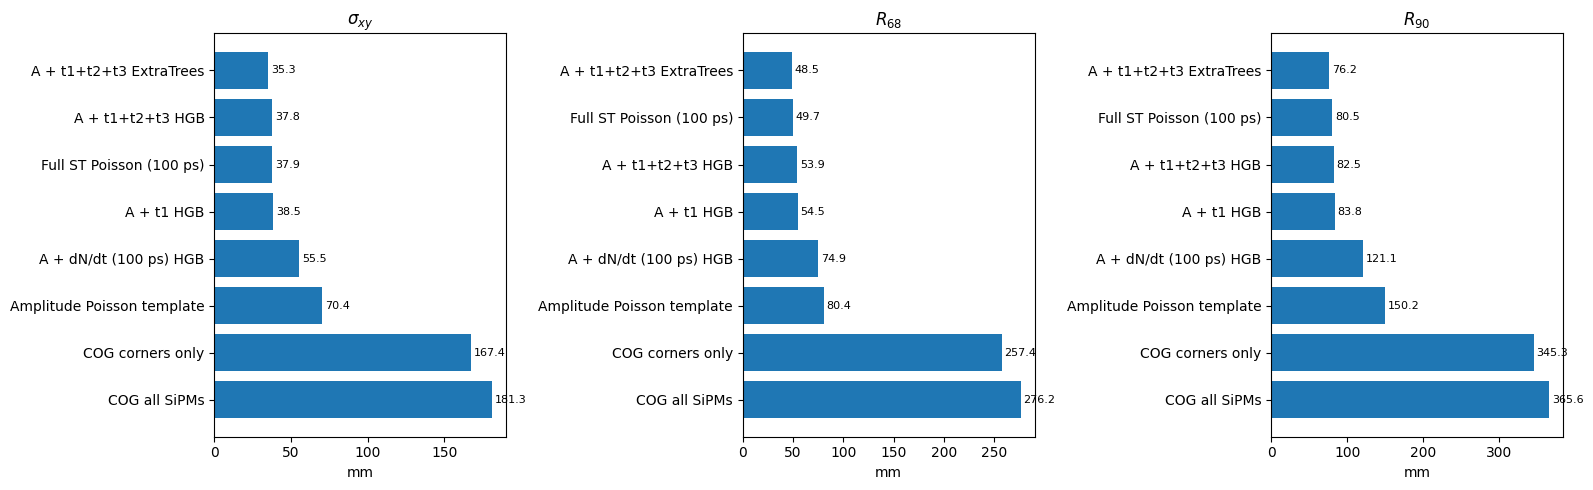

Best by R68: A + t1+t2+t3 ExtraTrees


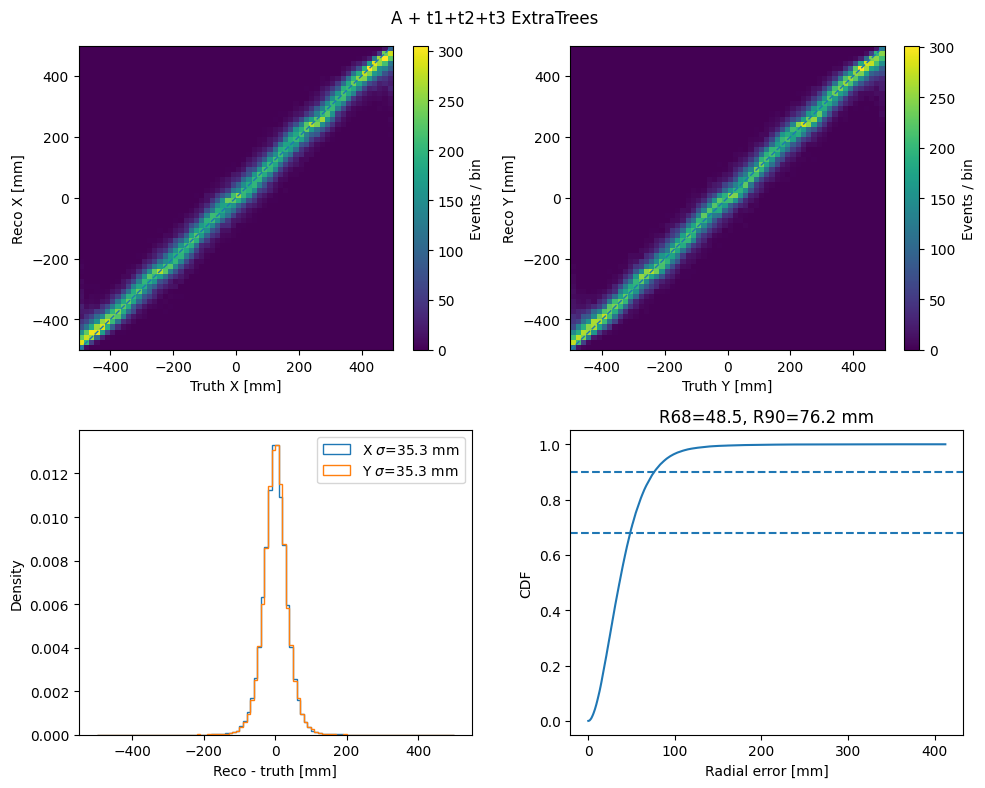

In [69]:

# 11. Summary + comparison
summary=pd.DataFrame([metrics(k,v) for k,v in pred.items()]).sort_values("R68_mm").reset_index(drop=True)
display(summary.round(2))
summary.to_csv(OUT/"spatiotemporal_reconstruction_summary.csv",index=False)

fig,ax=plt.subplots(1,3,figsize=(16,5))
for a,c,t in zip(ax,["sigma_xy_mm","R68_mm","R90_mm"],
                 [r"$\sigma_{xy}$",r"$R_{68}$",r"$R_{90}$"]):
    z=summary.sort_values(c)
    b=a.barh(z.method,z[c])
    a.bar_label(b,fmt="%.1f",padding=2,fontsize=8)
    a.invert_yaxis(); a.set(xlabel="mm",title=t)
plt.tight_layout()
plt.savefig(OUT/"reconstruction_comparison.png",dpi=180,bbox_inches="tight")
plt.show()

best=summary.iloc[0].method
print("Best by R68:",best)
performance(best,pred[best])


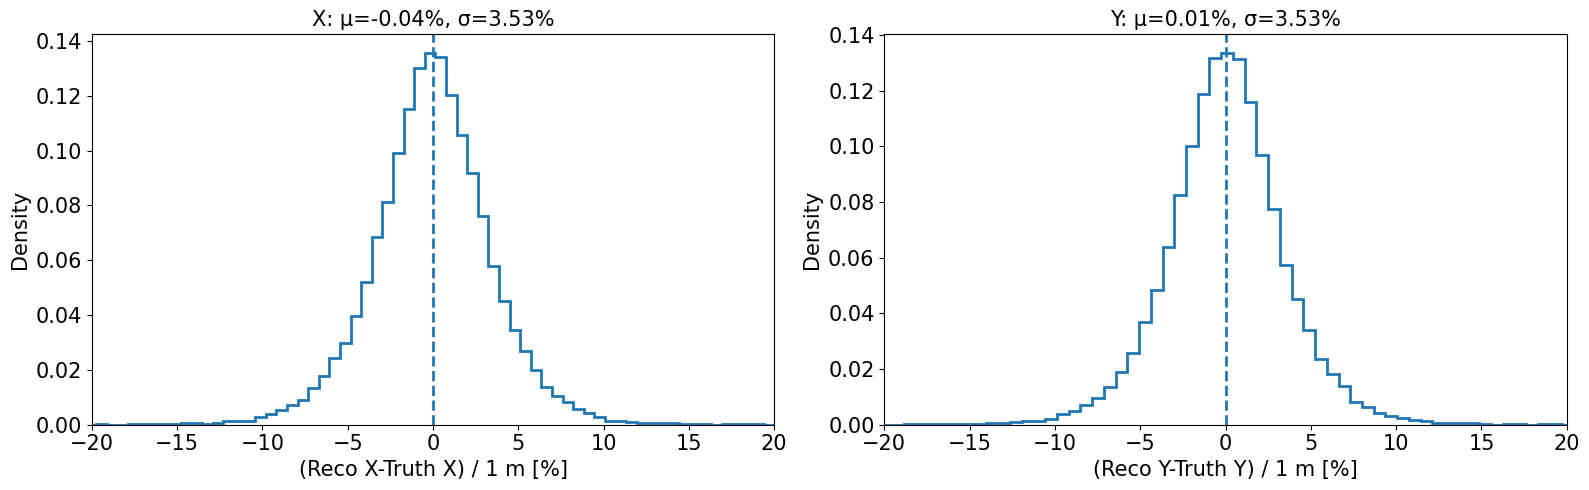

In [82]:
name="A + t1+t2+t3 ExtraTrees"
xy,tru=pred[name],truth[ite]
L=1000. # detector size [mm]

fig,ax=plt.subplots(1,2,figsize=(16,5))
for j,l in enumerate("XY"):
    r=100*(xy[:,j]-tru[:,j])/L
    ax[j].hist(r,100,histtype="step",density=True,linewidth=2)
    ax[j].axvline(0,ls="--",lw=2)
    ax[j].set(xlabel=f"(Reco {l}-Truth {l}) / 1 m [%]",ylabel="Density",
              title=f"{l}: μ={r.mean():.2f}%, σ={r.std():.2f}%")
    ax[j].set_xlim(-20,20)
    ax[j].tick_params(labelsize=15)
    ax[j].xaxis.label.set_size(15)
    ax[j].yaxis.label.set_size(15)
    ax[j].title.set_size(15)
plt.tight_layout()
plt.show()


## 12. Information-limit check: approximate Poisson CRLB

For independent Poisson observables with expected response \(\mu_k(x,y)\),

$$
I_{ab}
=
\sum_k
\frac{1}{\mu_k}
\frac{\partial\mu_k}{\partial a}
\frac{\partial\mu_k}{\partial b},
\qquad a,b\in\{x,y\}.
$$

The inverse Fisher matrix provides a local lower-bound estimate.

This is an **approximate diagnostic**, especially for the timing representation because every event was aligned to its earliest detected photon. Still, it is very useful for deciding whether a 10 mm target is even information-theoretically plausible with the current response.


Amplitude-only median CRLB sigma_xy: 35.44 mm
Full ST median CRLB sigma_xy: 0.48 mm
Full ST fraction of valid cells with CRLB < 10 mm: 100.0%


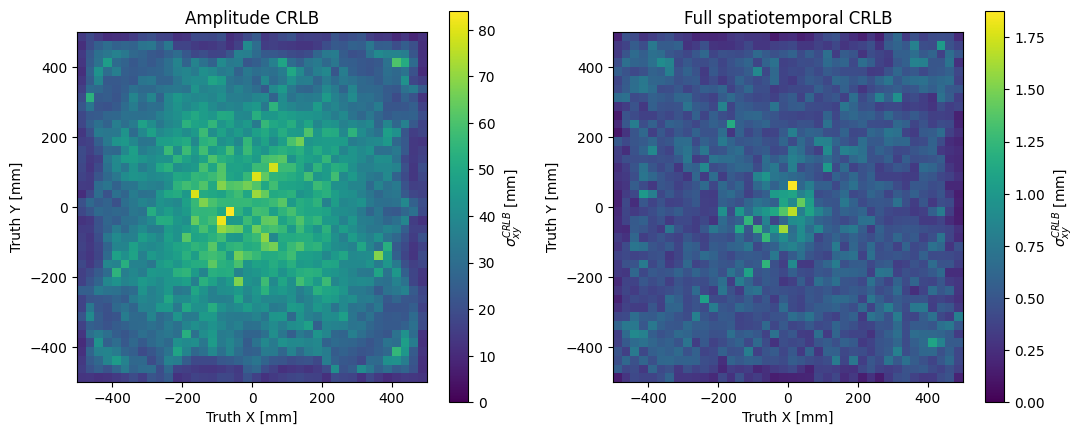

In [70]:

# 12. Approximate CRLB from a regular Poisson template grid
def crlb_map(mu_grid,count_grid,mincell=MIN_CELL):
    mu=np.asarray(mu_grid,float)
    valid=(count_grid>=mincell)&np.isfinite(mu).all(2)

    # NaNs deliberately propagate through gradients near missing cells
    dx=XY_CENTERS[1]-XY_CENTERS[0]
    dy=dx
    dmy,dmx=np.gradient(mu,dy,dx,axis=(0,1))

    lam=np.clip(mu,1e-6,None)
    Ixx=np.nansum(dmx*dmx/lam,axis=2)
    Iyy=np.nansum(dmy*dmy/lam,axis=2)
    Ixy=np.nansum(dmx*dmy/lam,axis=2)

    det=Ixx*Iyy-Ixy*Ixy
    sx=np.full_like(Ixx,np.nan,float)
    sy=np.full_like(Iyy,np.nan,float)

    m=valid&(det>0)&np.isfinite(det)
    sx[m]=np.sqrt(Iyy[m]/det[m])
    sy[m]=np.sqrt(Ixx[m]/det[m])
    sxy=np.sqrt((sx*sx+sy*sy)/2)
    return sx,sy,sxy

sxA,syA,sxyA=crlb_map(muAgrid,countA)
sxST,syST,sxyST=crlb_map(muSTgrid,countST)

print("Amplitude-only median CRLB sigma_xy:",
      f"{np.nanmedian(sxyA):.2f} mm")
print("Full ST median CRLB sigma_xy:",
      f"{np.nanmedian(sxyST):.2f} mm")
print("Full ST fraction of valid cells with CRLB < 10 mm:",
      f"{np.nanmean(sxyST<10):.1%}")

fig,ax=plt.subplots(1,2,figsize=(11,4.5))
for a,z,t in [
    (ax[0],sxyA,"Amplitude CRLB"),
    (ax[1],sxyST,"Full spatiotemporal CRLB")
]:
    im=a.imshow(z,origin="lower",extent=(-500,500,-500,500),
                aspect="equal",vmin=0)
    a.set(xlabel="Truth X [mm]",ylabel="Truth Y [mm]",title=t)
    plt.colorbar(im,ax=a,label=r"$\sigma_{xy}^{CRLB}$ [mm]")
plt.tight_layout()
plt.savefig(OUT/"approximate_CRLB_maps.png",dpi=180,bbox_inches="tight")
plt.show()



## 13. Optional \(dN/dt\) timing-bin scan

The master histogram is 50 ps/bin, so it can be rebinned without re-reading ROOT files.

Recommended factors:

- 1  \(\rightarrow\) 50 ps
- 2  \(\rightarrow\) 100 ps
- 4  \(\rightarrow\) 200 ps
- 6  \(\rightarrow\) 300 ps

This directly checks whether the current timing discretization is limiting the reconstruction.


50 ps R68 = 55.26 mm
100 ps R68 = 49.71 mm
200 ps R68 = 48.19 mm
300 ps R68 = 47.63 mm


,method,N,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,50 ps,60000,-0.52,0.42,42.26,42.82,42.54,55.26,89.27
1,100 ps,60000,-0.52,0.36,37.93,37.93,37.93,49.71,80.53
2,200 ps,60000,-0.44,0.20,36.34,36.18,36.26,48.19,77.67
3,300 ps,60000,-0.42,0.26,35.89,35.96,35.92,47.63,77.27


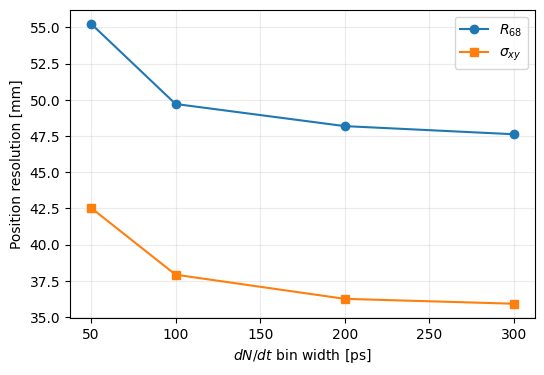

In [71]:
RUN_TIMING_BIN_SCAN = True
# 13. Optional timing-bin scan using full ST likelihood
if RUN_TIMING_BIN_SCAN:
    scan=[]
    for fac in [1,2,4,6]:
        if NBIN_FINE%fac: continue

        d=rebin_dnd(DND_FINE,fac)
        late=np.maximum(A-d.sum(2),0)
        k=np.hstack([d.reshape(len(d),-1).astype(float),late])

        p,m,_,_=build_templates(k)
        xy=poisson_reco(k[ite],p,m)
        met=metrics(f"{DT_FINE_NS*fac*1e3:.0f} ps",xy)
        scan.append(met)
        print(met["method"],"R68 =",f'{met["R68_mm"]:.2f} mm')

    scan=pd.DataFrame(scan)
    display(scan.round(2))

    fig,ax=plt.subplots(figsize=(6,4))
    x=scan.method.str.replace(" ps","",regex=False).astype(float)
    ax.plot(x,scan.R68_mm,"o-",label=r"$R_{68}$")
    ax.plot(x,scan.sigma_xy_mm,"s-",label=r"$\sigma_{xy}$")
    ax.set(xlabel=r"$dN/dt$ bin width [ps]",ylabel="Position resolution [mm]")
    ax.grid(alpha=.25); ax.legend()
    plt.show()
else:
    print("RUN_TIMING_BIN_SCAN=False -> skipped")



# How to interpret the result

The most important progression is

$$
A
\rightarrow
A+t_1
\rightarrow
A+t_1+t_2+t_3
\rightarrow
A+dN/dt
\rightarrow
L_{\rm full\,ST}.
$$

Typical interpretations:

- **\(A+t_1\) improves strongly over amplitude**: propagation timing carries independent position information.
- **\(t_2,t_3\) add further improvement**: the early-photon order statistics are useful beyond the first photon.
- **\(dN/dt\) improves further**: waveform/arrival-time shape contains information that simple timing summaries discard.
- **Full ST likelihood improves over regression**: the detector response is well described by the calibrated photon space-time templates.
- **CRLB \(\gg10\) mm**: a 10 mm target likely requires detector/optics/sensor changes, not merely a stronger reconstruction algorithm.
- **CRLB \(<10\) mm but algorithms remain much worse**: substantial algorithmic headroom remains.
